In [2]:
#%pip install pandas matplotlib
!mamba install pandas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.875 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [11]:
bio = pd.read_csv('midterm/BIO.csv')
bio["Ticker"] = 'BIO'

khc = pd.read_csv('midterm/KHC.csv')
khc['Ticker'] = 'KHC'

ntrs = pd.read_csv('midterm/NTRS.csv')
ntrs['Ticker'] = 'NTRS'

vrsn = pd.read_csv('midterm/VRSN.csv')
vrsn['Ticker'] = 'VRSN'

df = pd.concat([bio, khc, ntrs, vrsn])
df["Date"] = pd.to_datetime(df["Date"])
df = df.set_index("Date").sort_index()
df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Ticker
Date,,,,,,,,
2022-01-03,752.170,752.170,721.790,735.420,111000,0.0,0.0,BIO
2022-01-03,28.167,28.418,28.003,28.395,5957600,0.0,0.0,KHC
2022-01-03,248.018,249.364,245.249,247.616,332600,0.0,0.0,VRSN
2022-01-03,104.686,105.163,103.775,104.695,646100,0.0,0.0,NTRS
2022-01-04,247.576,248.588,244.748,245.966,546500,0.0,0.0,VRSN


In [16]:
for i in df.item():
    if bio['High'][i] == bio['Low'][i]:
        print(i)
        
    

<class 'AttributeError'>: 'DataFrame' object has no attribute 'item'

In [14]:
#Task 1 2
g = df.groupby("Ticker")
pd.DataFrame({
    "highest": g["High"].max(),
    "lowest": g["Low"].min(),
})

,highest,lowest
Ticker,,
BIO,752.170,211.430
KHC,35.627,22.181
NTRS,139.157,57.351
VRSN,305.895,152.482


In [19]:
#Task 1 4
g = df.groupby("Ticker")
pd.DataFrame({
    "highest_high": g["High"].max(),
    "date_of_high": g["High"].idxmax(),
    "lowest_low": g["Low"].min(),
    "date_of_low": g["Low"].idxmin(),
})

,highest_high,date_of_high,lowest_low,date_of_low
Ticker,,,,
BIO,752.170,2022-01-03,211.430,2025-06-03
KHC,35.627,2022-05-10,22.181,2025-11-06
NTRS,139.157,2025-12-23,57.351,2023-10-25
VRSN,305.895,2025-07-28,152.482,2022-06-17


In [ ]:
df['col']

<Axes: xlabel='Date'>

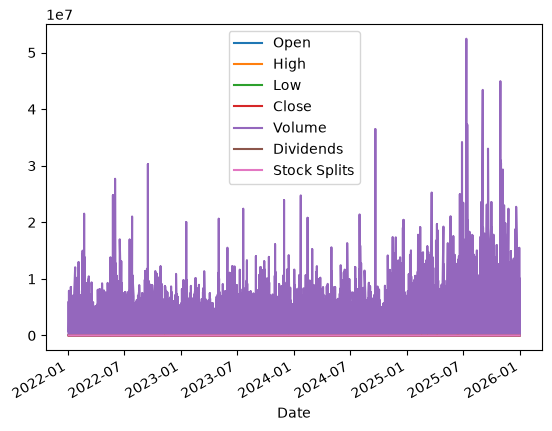

In [22]:
# fig, ax = plt.subplots()
# ax.plot(df['BIO'], label='BIO', color='green')
# ax.plot(df['KHC'], label='KHC', color='red')
# ax.plot(df['NTRS'], label='NTRS', color='blue')
# ax.plot(df['VRSN'], label='VRSN', color='yellow')
df.plot()

In [23]:
#Task 2 1
df.isna().sum()

Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
Ticker          0
dtype: int64

In [25]:
#Task 2 2
df_miss = df[df.columns[df.isna().sum() == 0]]
print(df_miss)


               Open     High      Low    Close    Volume  Dividends  \
Date                                                                  
2022-01-03  752.170  752.170  721.790  735.420    111000        0.0   
2022-01-03   28.167   28.418   28.003   28.395   5957600        0.0   
2022-01-03  248.018  249.364  245.249  247.616    332600        0.0   
2022-01-03  104.686  105.163  103.775  104.695    646100        0.0   
2022-01-04  247.576  248.588  244.748  245.966    546500        0.0   
...             ...      ...      ...      ...       ...        ...   
2025-12-29  303.880  305.620  301.070  303.730    148800        0.0   
2025-12-30   23.004   23.332   22.980   23.228  10109500        0.0   
2025-12-30  301.270  305.000  300.320  304.510     97400        0.0   
2025-12-30  137.738  137.778  135.994  136.083    420300        0.0   
2025-12-30  242.345  243.881  241.652  243.643    365200        0.0   

            Stock Splits Ticker  
Date                             
2022-01-

In [33]:
#Task 3 1
rng = np.random.default_rng(500)
rand = rng.integers(100, 501, size=4)
print(rand)

[364 327 264 442]


(array([1., 2., 6., 8., 4., 4., 7., 4., 7., 5., 0., 4., 5., 6., 4., 3., 6.,
        6., 4., 5., 2., 0., 2., 2., 1., 0., 0., 1., 1., 1.]),
 array([0.00633393, 0.03047475, 0.05461556, 0.07875638, 0.10289719,
        0.127038  , 0.15117882, 0.17531963, 0.19946045, 0.22360126,
        0.24774207, 0.27188289, 0.2960237 , 0.32016452, 0.34430533,
        0.36844614, 0.39258696, 0.41672777, 0.44086859, 0.4650094 ,
        0.48915021, 0.51329103, 0.53743184, 0.56157266, 0.58571347,
        0.60985428, 0.6339951 , 0.65813591, 0.68227673, 0.70641754,
        0.73055836]),
 <BarContainer object of 30 artists>)

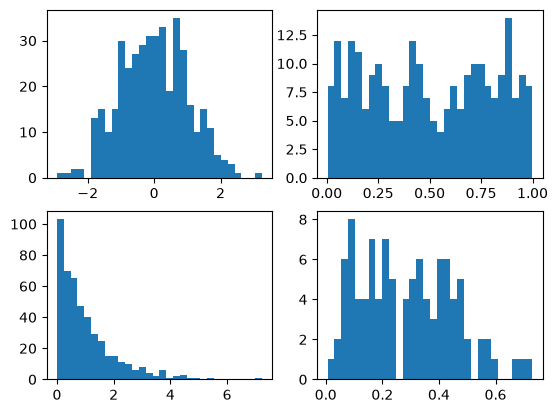

In [34]:
#Task 3 2
n1, n2, n3, n4 = np.random.randint(100, 501, size=4)

x1 = np.random.normal(0, 1, n1)
x2 = np.random.uniform(0, 1, n2)
x3 = np.random.exponential(1, n3)
x4 = np.random.beta(2, 5, n4)

fig, ax = plt.subplots(2, 2)
ax[0, 0].hist(x1, bins=30)
ax[0, 1].hist(x2, bins=30)
ax[1, 0].hist(x3, bins=30)
ax[1, 1].hist(x4, bins=30)

In [41]:
#Task 1 3
# log_returns = np.diff(np.log(Close), axis=0)
# print(log_returns)

df["ret"] = df.groupby("Ticker")["Close"].log()
df.groupby("Ticker").agg(["mean", "std", "min", "max"])

<class 'AttributeError'>: 'SeriesGroupBy' object has no attribute 'log'

In [48]:
#Task Bonus 1
x = []
for i in range(2, 21):
    y = []
    for j in range(2, i + 1):
        if i % j == 0:
            y.append(j)
    if len(y) == 1:
        y = []
    x.append(y)
print(x)            

[[], [], [2, 4], [], [2, 3, 6], [], [2, 4, 8], [3, 9], [2, 5, 10], [], [2, 3, 4, 6, 12], [], [2, 7, 14], [3, 5, 15], [2, 4, 8, 16], [], [2, 3, 6, 9, 18], [], [2, 4, 5, 10, 20]]


In [52]:
#Task Bonus 2
x = {}
for i in range(2, 21):
    y = []
    for j in range(2, i + 1):
        if i % j == 0:
            y.append(j)
    x[i] = y
print(x)

{2: [2], 3: [3], 4: [2, 4], 5: [5], 6: [2, 3, 6], 7: [7], 8: [2, 4, 8], 9: [3, 9], 10: [2, 5, 10], 11: [11], 12: [2, 3, 4, 6, 12], 13: [13], 14: [2, 7, 14], 15: [3, 5, 15], 16: [2, 4, 8, 16], 17: [17], 18: [2, 3, 6, 9, 18], 19: [19], 20: [2, 4, 5, 10, 20]}
